Observación inicial: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
Acciones disponibles: Discrete(2)
Forma de la observación: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)


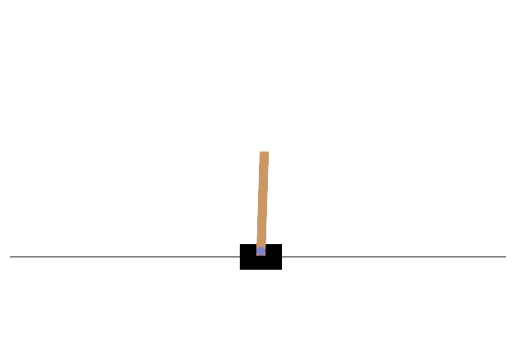

In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt

# Crear CartPole y obtener su primera imagen.
entorno = gym.make("CartPole-v1", render_mode="rgb_array")
observacion, informacion = entorno.reset(seed=42)
imagen = entorno.render()

print("Observación inicial:", observacion)
print("Acciones disponibles:", entorno.action_space)
print("Forma de la observación:", entorno.observation_space)

plt.imshow(imagen)
plt.axis("off")
plt.show()

entorno.close()

In [2]:
import time
import gymnasium as gym

entorno = gym.make("CartPole-v1", render_mode="human")
resultados = []

for numero_episodio in range(1, 6):
    observacion, informacion = entorno.reset(seed=40 + numero_episodio)
    recompensa_total = 0
    paso = 0
    terminado = False
    truncado = False

    print(f"\n--- Episodio {numero_episodio} ---")

    while not (terminado or truncado):
        accion = entorno.action_space.sample()
        observacion, recompensa, terminado, truncado, informacion = (
            entorno.step(accion)
        )

        paso += 1
        recompensa_total += recompensa

        print(
            f"Paso {paso}: "
            f"observación={observacion.round(3)}, "
            f"acción={accion}, "
            f"recompensa={recompensa}, "
            f"terminado={terminado}, "
            f"truncado={truncado}"
        )

        time.sleep(0.03)

    resultados.append({
        "episodio": numero_episodio,
        "pasos": paso,
        "recompensa_total": recompensa_total,
    })

    print(f"Recompensa total: {recompensa_total}")

entorno.close()


--- Episodio 1 ---
Paso 1: observación=[ 0.046  0.222 -0.037 -0.272], acción=1, recompensa=1.0, terminado=False, truncado=False
Paso 2: observación=[ 0.05   0.418 -0.042 -0.576], acción=1, recompensa=1.0, terminado=False, truncado=False
Paso 3: observación=[ 0.059  0.224 -0.054 -0.296], acción=0, recompensa=1.0, terminado=False, truncado=False
Paso 4: observación=[ 0.063  0.419 -0.06  -0.606], acción=1, recompensa=1.0, terminado=False, truncado=False
Paso 5: observación=[ 0.072  0.615 -0.072 -0.916], acción=1, recompensa=1.0, terminado=False, truncado=False
Paso 6: observación=[ 0.084  0.421 -0.09  -0.647], acción=0, recompensa=1.0, terminado=False, truncado=False
Paso 7: observación=[ 0.092  0.617 -0.103 -0.967], acción=1, recompensa=1.0, terminado=False, truncado=False
Paso 8: observación=[ 0.105  0.424 -0.122 -0.708], acción=0, recompensa=1.0, terminado=False, truncado=False
Paso 9: observación=[ 0.113  0.231 -0.137 -0.456], acción=0, recompensa=1.0, terminado=False, truncado=False

In [3]:
import pandas as pd

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados)

print(
    "Recompensa promedio:",
    tabla_resultados["recompensa_total"].mean()
)

,episodio,pasos,recompensa_total
0,1,20,20.0
1,2,12,12.0
2,3,31,31.0
3,4,31,31.0
4,5,21,21.0


Recompensa promedio: 23.0


## Interpretación

Se ejecutaron cinco episodios de CartPole con acciones aleatorias.
La recompensa fue de 1 punto por cada paso que el poste permaneció
equilibrado.

Las recompensas obtenidas fueron 20, 12, 31, 31 y 21 puntos,
con un promedio de 23. El agente no aprendió de los episodios
anteriores; por eso su desempeño varía entre intentos.

En esta práctica observamos el ciclo del aprendizaje por refuerzo:
el agente recibe una observación, elige una acción y obtiene una
recompensa junto con una nueva observación.